# Contours and Shape Detection

A contour is the outline curve of a connected white region in a binary image. Contours turn pixels into objects: once you have an outline you can measure area, perimeter, centre and bounding boxes, approximate the shape, and classify it - square, circle, triangle - from its corners. This is the workhorse of classic computer vision.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Finding and drawing contours

`cv2.findContours` returns the contours and their hierarchy from a binary image. Retrieval mode matters: `RETR_EXTERNAL` keeps only outer outlines, `RETR_TREE` keeps all nested contours. Approximation `CHAIN_APPROX_SIMPLE` stores only endpoints of straight runs, saving memory.

Contours found: 4


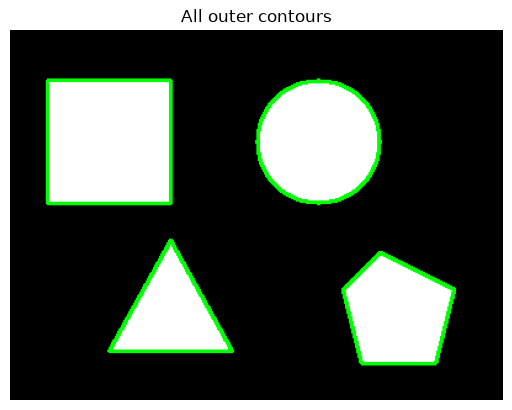

In [2]:
img = cv2.imread("../assets/contours_shapes.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
_, binary = cv2.threshold(gray, 127, 255, cv2.THRESH_BINARY)
contours, hierarchy = cv2.findContours(binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
print("Contours found:", len(contours))
drawn = img.copy()
cv2.drawContours(drawn, contours, -1, (0, 255, 0), 2)
show(drawn, "All outer contours")

## Measuring contours: area, perimeter, centroid

`cv2.contourArea` and `cv2.arcLength(contour, closed=True)` give size measures. Moments give the centroid. Sorting contours by area descending is the standard way to work on the biggest object first and ignore specks.

In [3]:
for i, c in enumerate(sorted(contours, key=cv2.contourArea, reverse=True)):
    m = cv2.moments(c)
    cx, cy = int(m["m10"] / m["m00"]), int(m["m01"] / m["m00"])
    print(f"Contour {i}: area={cv2.contourArea(c):7.0f}  perimeter={cv2.arcLength(c, True):6.1f}  centroid=({cx}, {cy})")

Contour 0: area=  10000  perimeter= 400.0  centroid=(80, 90)
Contour 1: area=   7704  perimeter= 329.7  centroid=(250, 90)
Contour 2: area=   5880  perimeter= 307.3  centroid=(313, 229)
Contour 3: area=   4500  perimeter= 321.4  centroid=(130, 229)


## Bounding boxes, circles and rotated rectangles

`cv2.boundingRect` gives an upright box (x, y, w, h). `cv2.minAreaRect` gives a rotated box that hugs tilted objects; `cv2.minEnclosingCircle` gives the smallest covering circle. Detection UIs draw the upright box; measurement tasks prefer the rotated one.

Bounding rect: (30, 40, 101, 101) | enclosing circle centre: (80, 90) radius: 71


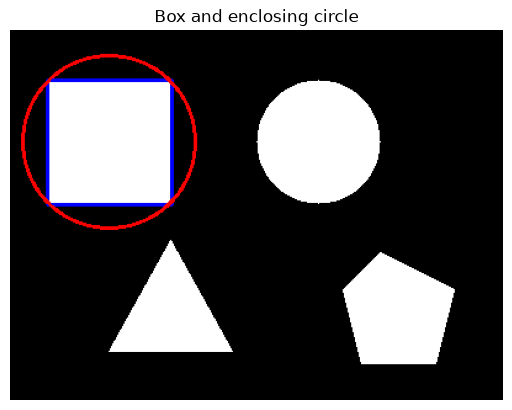

In [4]:
biggest = max(contours, key=cv2.contourArea)
x, y, w, h = cv2.boundingRect(biggest)
(cx, cy), radius = cv2.minEnclosingCircle(biggest)
out = img.copy()
cv2.rectangle(out, (x, y), (x + w, y + h), (255, 0, 0), 2)
cv2.circle(out, (int(cx), int(cy)), int(radius), (0, 0, 255), 2)
print("Bounding rect:", (x, y, w, h), "| enclosing circle centre:", (round(cx), round(cy)), "radius:", round(radius))
show(out, "Box and enclosing circle")

## Polygon approximation and shape classification

`cv2.approxPolyDP` simplifies a contour to its dominant corners; epsilon is a fraction of the perimeter. The corner count classifies the shape: 3 = triangle, 4 = quadrilateral (check width/height ratio to separate square from rectangle), many = circle. This is a complete shape-recognition system in a few lines.

Pentagon with 5 corners
Triangle with 3 corners
Circle / other with 8 corners
Square with 4 corners


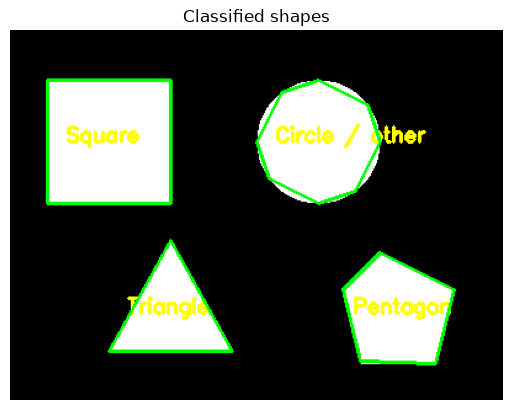

In [5]:
def classify(contour):
    approx = cv2.approxPolyDP(contour, 0.02 * cv2.arcLength(contour, True), True)
    n = len(approx)
    if n == 3: return "Triangle", approx
    if n == 4:
        _, _, w, h = cv2.boundingRect(approx)
        return ("Square" if abs(w - h) <= 8 else "Rectangle"), approx
    if n == 5: return "Pentagon", approx
    return "Circle / other", approx

labelled = img.copy()
for c in contours:
    name, approx = classify(c)
    m = cv2.moments(c)
    cv2.putText(labelled, name, (int(m["m10"] / m["m00"]) - 35, int(m["m01"] / m["m00"])),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 255, 255), 2)
    cv2.drawContours(labelled, [approx], -1, (0, 255, 0), 2)
    print(name, "with", len(approx), "corners")
show(labelled, "Classified shapes")

## Convex hull and solidity

The convex hull is the smallest convex curve wrapping the contour - like a rubber band around the shape. Solidity = contour area / hull area: near 1 for solid shapes, much lower for stars, hands and letters. Hull defects (the gaps between hull and contour) are how finger counting works.

Solidity of the biggest shape: 1.0


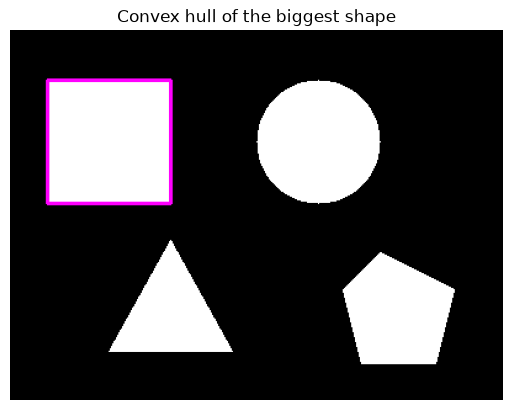

In [6]:
c = max(contours, key=cv2.contourArea)
hull = cv2.convexHull(c)
solidity = cv2.contourArea(c) / cv2.contourArea(hull)
print("Solidity of the biggest shape:", round(float(solidity), 3))
out2 = img.copy()
cv2.drawContours(out2, [hull], -1, (255, 0, 255), 2)
show(out2, "Convex hull of the biggest shape")

## Filtering contours and a counting pipeline

Real pipelines filter by area to drop noise, then count what remains. Combined with thresholding and morphology this counts coins, cells, products on a belt - the most common industrial OpenCV job.

In [7]:
gray_n = cv2.cvtColor(cv2.imread("../assets/noisy_image.png"), cv2.COLOR_BGR2GRAY)
_, bw = cv2.threshold(gray_n, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
bw = cv2.morphologyEx(bw, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
cs, _ = cv2.findContours(bw, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
objects = [c for c in cs if cv2.contourArea(c) > 300]
print("Contours total:", len(cs), "| objects with area > 300:", len(objects))

Contours total: 2 | objects with area > 300: 2


## Key Points

- findContours works on binary images; RETR_EXTERNAL keeps only outer outlines.
- contourArea, arcLength and moments measure size and centre.
- approxPolyDP corner count classifies shapes: 3 triangle, 4 quad, 5 pentagon, many circle.
- boundingRect is upright; minAreaRect follows tilted objects.
- Filter contours by area before counting - it removes most noise.

## Mini Task

1. Count the shapes in `contours_shapes.png` and print each area sorted descending.
2. Classify every shape and draw its name at its centroid.
3. Change the approxPolyDP epsilon to 0.05 and note which classifications change, and why.